# PROJET-GNN
To get started, you need to install pytorch geometric:
- https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html.

You can then have a look at the tutorial:
- https://pytorch-geometric.readthedocs.io/en/latest/get_started/introduction.html.

Check in particular sections:
- Data Handling of Graphs
- Data Transforms
- Learning Methods on Graphs

don't hesitate to check [practical slides](./GCNcode.pdf)

In [9]:
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns
import torch as th
import torch.nn.functional as F
from matplotlib.cm import ScalarMappable
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder
from torch import nn
from torch_geometric.nn import VGAE, GCNConv
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import from_networkx, to_networkx
import numpy as np
from torch_geometric.data import Data
from collections import Counter

## Getting started

In [11]:
# Chargement des données
G = nx.read_graphml("./airportsAndCoordAndPop.graphml", node_type=int)

# Infos générales
print(G)
print(f"Attributs des nœuds : {list(G.nodes(data=True))[:1]}")

Graph with 3363 nodes and 13547 edges
Attributs des nœuds : [(0, {'lon': -145.50972222222222, 'lat': -17.35388888888889, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Anaa'})]


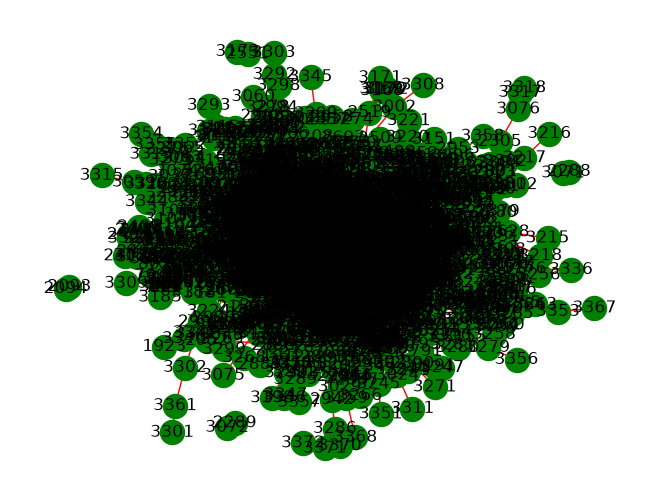

In [12]:
pos = nx.spring_layout(G, k=3.0, seed=42)
nx.draw(G, pos=pos, with_labels=True, node_color='green', edge_color='red')

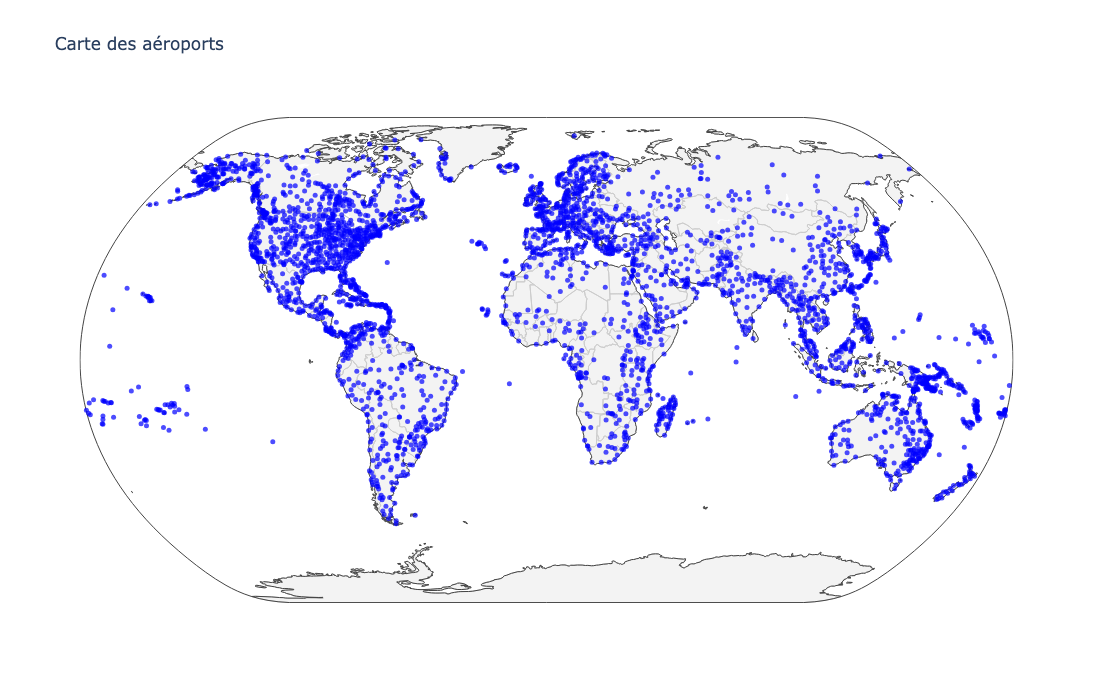

In [13]:
import plotly.graph_objects as go
import networkx as nx

# Récupération des coordonnées depuis les attributs des nœuds
lons = [data['lon'] for _, data in G.nodes(data=True)]
lats = [data['lat'] for _, data in G.nodes(data=True)]

# Textes survolés (ex: nom de ville et pays)
textes = [
    f"{data['city_name']}, {data['country']}<br>Population: {data['population']}"
    for _, data in G.nodes(data=True)
]

# Création de la trace des nœuds
node_trace = go.Scattergeo(
    lon=lons,
    lat=lats,
    text=textes,
    mode='markers',
    marker=dict(
        size=5,
        color='blue',
        opacity=0.7
    ),
    hoverinfo='text'
)

# Assemblage de la figure
fig = go.Figure(data=[node_trace])
fig.update_layout(
    title='Carte des aéroports',
    geo=dict(
        projection_type='natural earth',  # ou 'equirectangular', 'orthographic', etc.
        showland=True,
        landcolor='rgb(243, 243, 243)',
        showcountries=True,
        countrycolor='rgb(204, 204, 204)'
    ),
    height=700
)
fig.show()

Pour la suite, nous décidons de prédire le pays en fonction des coordonnées géographiques.

Objectif : entraîner un GCN à prédire le pays (country) d'une ville à partir de : ses features (coordonnées lon, lat, éventuellement population), et de la structure du graphe (relations entre villes).

Les villes du même pays ont tendance à être proches géographiquement et connectées entre elles.

In [14]:
data = from_networkx(
    G,
    group_node_attrs=["lon", "lat", "population"],
)
print(data)

Data(edge_index=[2, 27094], country=[3363], city_name=[3363], x=[3363, 3])


In [15]:
comptage = Counter(data.country)

for pays, nb in comptage.most_common():
    print(f"{pays}: {nb}")

total = sum(comptage.values())
print(f"\nTotal: {total} lignes (attendu : {G.number_of_nodes()})")

USA: 650
CANADA: 243
AUSTRALIA: 207
BRAZIL: 105
CHINA: 93
PAPUA_NEW_GUINEA: 92
RUSSIA: 70
JAPAN: 69
M&Eacute;XICO#MEXICO: 59
ARGENTINA: 57
INDIA: 57
FRANCE: 56
INDONESIA: 47
NORWAY: 46
COLOMBIA: 42
UNITED_KINGDOM: 40
MADAGASCAR: 40
PHILIPPINES: 34
MALAYSIA: 33
SWEDEN: 33
GREECE: 33
SPAIN: 32
ITALY: 31
PAKISTAN: 31
NEW_ZEALAND: 28
GERMANY: 28
VENEZUELA: 28
VANUATU: 27
DENMARK: 27
ETHIOPIA: 27
ALGERIA: 27
SAUDI_ARABIA: 26
TURKEY: 25
THAILAND: 24
IRAN: 22
BAHAMAS: 22
FRENCH_POLYNESIA: 21
FINLAND: 21
SOUTH_AFRICA: 21
MYANMAR: 21
MARSHALL_ISLANDS: 20
CHILE: 17
PER&Uacute;#PERU: 17
FIJI: 16
UKRAINE: 16
SOLOMON_ISLANDS: 15
TANZANIA: 15
SOUTH_KOREA: 14
PANAMA: 13
CUBA: 13
ROMANIA: 13
PORTUGAL: 13
CONGO,_DEMOCRATIC_PEOPLES'S_REPUBLIC: 13
SUDAN: 13
VI&Ecirc;T_NAM#VIET_NAM,VIETNAM: 12
COSTA_RICA: 12
MOROCCO: 12
ICELAND: 12
TAIWAN: 11
BOLIVIA: 11
HONDURAS: 11
KENYA: 11
NEW_CALEDONIA: 10
NEPAL: 10
KAZAKHSTAN: 10
GABON: 10
ZAMBIA: 10
EGYPT: 9
UZBEKHISTAN: 9
POLAND: 9
MOZAMBIQUE: 9
NIGERIA: 9
YEMEN: 

In [16]:
counts = np.array(list(comptage.values()))
print(f"Max: {counts.max()}, Min: {counts.min()}")
print(f"Ratio déséquilibre: {counts.max()/counts.min():.0f}:1")
print(f"Médiane: {np.median(counts)}, Moyenne: {counts.mean():.1f}")
print(f"Pays avec <5 nœuds: {(counts<5).sum()} / {len(counts)}")

Max: 650, Min: 1
Ratio déséquilibre: 650:1
Médiane: 4.0, Moyenne: 15.9
Pays avec <5 nœuds: 113 / 212


In [18]:
from collections import Counter
import torch
import numpy as np

# Récupérer les labels (dans l'ordre des nœuds du graphe)
labels_str = [d['country'] for _, d in G.nodes(data=True)]

# Mapping
classes = sorted(set(labels_str))
pays2idx = {p: i for i, p in enumerate(classes)}
idx2pays = {i: p for p, i in pays2idx.items()}

y = torch.tensor([pays2idx[p] for p in labels_str], dtype=torch.long)
print(f"Nombre de classes : {len(classes)}")
print(f"Nombre de nœuds : {len(y)}")

Nombre de classes : 212
Nombre de nœuds : 3363


In [28]:
"""
Classification de nœuds (pays d'aéroports)
============================================================
- Fusion hiérarchique en 2 niveaux : pays rare → sous-région ONU → macro-région
- Features géographiques enrichies (sin/cos, log pop, ratios)
- Modèle GCN multi-tâche (classification + régression lat/lon)
- Poids de classes par racine carrée + Focal Loss
- Early stopping, scheduler, dropout, weight decay
- Rapport détaillé par région géographique
"""

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

import numpy as np
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.utils import from_networkx
from torch_geometric.nn import GCNConv
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, balanced_accuracy_score, classification_report

# ============================================================
# 1. CONFIGURATION
# ============================================================
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

CHEMIN_GRAPHE = "./airportsAndCoordAndPop.graphml"
SEUIL = 3
GAMMA = 2.0
USE_FOCAL = True
EPOCHS = 400
PATIENCE = 40
LR = 1e-3
WD = 1e-3
HIDDEN = 128
DROPOUT = 0.6
LAMBDA_REG = 0.5

# ============================================================
# 2. TAXONOMIE ONU — MAPPING DES PAYS RARES PAR SOUS-RÉGION
# ============================================================
REGION_MAPPING = {
    # ---------------- OCÉANIE ----------------
    'WALLIS_AND_FUTUNA_ISLANDS': 'OCEANIA_POLYNESIA',
    'NIUE': 'OCEANIA_POLYNESIA',
    'TUVALU': 'OCEANIA_POLYNESIA',
    'SAMOA': 'OCEANIA_POLYNESIA',
    'AMERICAN_SAMOA': 'OCEANIA_POLYNESIA',
    'TONGA': 'OCEANIA_POLYNESIA',
    'COOK_ISLANDS': 'OCEANIA_POLYNESIA',
    'FRENCH_POLYNESIA': 'OCEANIA_POLYNESIA',
    'FIJI': 'OCEANIA_MELANESIA',
    'SOLOMON_ISLANDS': 'OCEANIA_MELANESIA',
    'VANUATU': 'OCEANIA_MELANESIA',
    'NEW_CALEDONIA': 'OCEANIA_MELANESIA',
    'PAPUA_NEW_GUINEA': 'OCEANIA_MELANESIA',
    'MARIANA_ISLANDS': 'OCEANIA_MICRONESIA',
    'GUAM': 'OCEANIA_MICRONESIA',
    'NAURU': 'OCEANIA_MICRONESIA',
    'KIRIBATI': 'OCEANIA_MICRONESIA',
    'PALAU': 'OCEANIA_MICRONESIA',
    'MARSHALL_ISLANDS': 'OCEANIA_MICRONESIA',
    'MICRONESIA': 'OCEANIA_MICRONESIA',

    # ---------------- AMÉRIQUES ----------------
    'SAINT-PIERRE_AND_MIQUELON#ST-PIERRE_AND_MIQUELON': 'AMERICAS_NORTH',
    'BERMUDA': 'AMERICAS_NORTH',
    'EL_SALVADOR': 'AMERICAS_CENTRAL',
    'NICARAGUA': 'AMERICAS_CENTRAL',
    'BELIZE': 'AMERICAS_CENTRAL',
    'CAYMAN_ISLANDS': 'AMERICAS_CARIBBEAN',
    'TRINIDAD_AND_TOBAGO': 'AMERICAS_CARIBBEAN',
    'SAINT_KITTS_AND_NEVIS#ST_KITTS_AND_NEVIS': 'AMERICAS_CARIBBEAN',
    'ANTIGUA_AND_BARBUDA': 'AMERICAS_CARIBBEAN',
    'BARBADOS': 'AMERICAS_CARIBBEAN',
    'GRENADA': 'AMERICAS_CARIBBEAN',
    'SAINT_LUCIA#ST_LUCIA': 'AMERICAS_CARIBBEAN',
    'US_VIRGIN_ISLANDS': 'AMERICAS_CARIBBEAN',
    'MARTINIQUE': 'AMERICAS_CARIBBEAN',
    'ANGUILLA': 'AMERICAS_CARIBBEAN',
    'DOMINICA': 'AMERICAS_CARIBBEAN',
    'GUYANA': 'AMERICAS_SOUTH',
    'SURINAME': 'AMERICAS_SOUTH',
    'PARAGUAY': 'AMERICAS_SOUTH',
    'URUGUAY': 'AMERICAS_SOUTH',
    'ECUADOR': 'AMERICAS_SOUTH',
    'FALKLAND_ISLANDS': 'AMERICAS_SOUTH',

    # ---------------- EUROPE ----------------
    'BELGIUM': 'EUROPE_WEST',
    'LUXEMBOURG': 'EUROPE_WEST',
    'THE_NETHERLANDS': 'EUROPE_WEST',
    'MALTA': 'EUROPE_SOUTH',
    'SLOVENIA': 'EUROPE_SOUTH',
    'ALBANIA': 'EUROPE_SOUTH',
    'MACEDONIA': 'EUROPE_SOUTH',
    'KOSOVO': 'EUROPE_SOUTH',
    'MOLDOVA': 'EUROPE_EAST',
    'BELARUS': 'EUROPE_EAST',
    'HUNGARY': 'EUROPE_EAST',
    'ESTONIA': 'EUROPE_NORTH',
    'LATVIA': 'EUROPE_NORTH',
    'LITHUANIA': 'EUROPE_NORTH',

    # ---------------- AFRIQUE ----------------
    'WESTERN_SAHARA': 'AFRICA_NORTH',
    'GUINEA_BISSAU': 'AFRICA_WEST',
    'BURKINA_FASO': 'AFRICA_WEST',
    'GHANA': 'AFRICA_WEST',
    'THE_GAMBIA': 'AFRICA_WEST',
    'LIBERIA': 'AFRICA_WEST',
    'IVORY_COAST': 'AFRICA_WEST',
    'BENIN': 'AFRICA_WEST',
    'NIGER': 'AFRICA_WEST',
    'GUINEA': 'AFRICA_WEST',
    'SIERRA_LEONE': 'AFRICA_WEST',
    'TOGO': 'AFRICA_WEST',
    'MAURITANIA': 'AFRICA_WEST',
    'CAPE_VERDE': 'AFRICA_WEST',
    'SENEGAL': 'AFRICA_WEST',
    'SAO_TOME_AND_PRINCIPE': 'AFRICA_CENTRAL',
    'EQUATORIAL_GUINEA': 'AFRICA_CENTRAL',
    'CHAD': 'AFRICA_CENTRAL',
    'CAMEROON': 'AFRICA_CENTRAL',
    'GABON': 'AFRICA_CENTRAL',
    'CONGO,_REPUBLIC_OF_THE': 'AFRICA_CENTRAL',
    'COMOROS': 'AFRICA_EAST',
    'REUNION': 'AFRICA_EAST',
    'DJIBOUTI': 'AFRICA_EAST',
    'BURUNDI': 'AFRICA_EAST',
    'RWANDA': 'AFRICA_EAST',
    'SEYCHELLES': 'AFRICA_EAST',
    'MAURITIUS': 'AFRICA_EAST',
    'ERITREA': 'AFRICA_EAST',
    'SOMALIA': 'AFRICA_EAST',
    'UGANDA': 'AFRICA_EAST',
    'MALAWI': 'AFRICA_EAST',
    'ZIMBABWE': 'AFRICA_EAST',
    'LESOTHO': 'AFRICA_SOUTH',
    'SWAZILAND': 'AFRICA_SOUTH',
    'BOTSWANA': 'AFRICA_SOUTH',
    'NAMIBIA': 'AFRICA_SOUTH',

    # ---------------- ASIE ----------------
    'JORDAN': 'ASIA_WEST',
    'BAHRAIN': 'ASIA_WEST',
    'LEBANON': 'ASIA_WEST',
    'QATAR': 'ASIA_WEST',
    'KUWAIT': 'ASIA_WEST',
    'ARMENIA': 'ASIA_WEST',
    'AZERBAIJAN': 'ASIA_WEST',
    'GEORGIA': 'ASIA_WEST',
    'CYPRUS': 'ASIA_WEST',
    'KYRGYZSTAN': 'ASIA_CENTRAL',
    'TURKMENISTAN': 'ASIA_CENTRAL',
    'TAJIKISTAN': 'ASIA_CENTRAL',
    'AFGHANISTAN': 'ASIA_CENTRAL',
    'UZBEKHISTAN': 'ASIA_CENTRAL',
    'KAZAKHSTAN': 'ASIA_CENTRAL',
    'MONGOLIA': 'ASIA_EAST',
    'NORTH_KOREA': 'ASIA_EAST',
    'SRI_LANKA': 'ASIA_SOUTH',
    'MALDIVES': 'ASIA_SOUTH',
    'BHUTAN': 'ASIA_SOUTH',
    'NEPAL': 'ASIA_SOUTH',
    'BANGLADESH': 'ASIA_SOUTH',
    'SINGAPORE': 'ASIA_SOUTHEAST',
    'BRUNEI': 'ASIA_SOUTHEAST',
    'EAST_TIMOR': 'ASIA_SOUTHEAST',
    'CAMBODIA': 'ASIA_SOUTHEAST',
    'LAOS': 'ASIA_SOUTHEAST',

    # ---------------- TERRITOIRES ISOLÉS ----------------
    'SAINT_HELENA#ST_HELENA': 'TERRITORIES_ATLANTIC',
}

# Mapping sous-région ONU → macro-région (continent)
SOUS_VERS_MACRO = {
    'OCEANIA_POLYNESIA': 'OCEANIA',
    'OCEANIA_MELANESIA': 'OCEANIA',
    'OCEANIA_MICRONESIA': 'OCEANIA',
    'AMERICAS_NORTH': 'AMERICAS',
    'AMERICAS_CENTRAL': 'AMERICAS',
    'AMERICAS_CARIBBEAN': 'AMERICAS',
    'AMERICAS_SOUTH': 'AMERICAS',
    'EUROPE_NORTH': 'EUROPE',
    'EUROPE_WEST': 'EUROPE',
    'EUROPE_SOUTH': 'EUROPE',
    'EUROPE_EAST': 'EUROPE',
    'AFRICA_NORTH': 'AFRICA',
    'AFRICA_WEST': 'AFRICA',
    'AFRICA_EAST': 'AFRICA',
    'AFRICA_CENTRAL': 'AFRICA',
    'AFRICA_SOUTH': 'AFRICA',
    'ASIA_WEST': 'ASIA',
    'ASIA_CENTRAL': 'ASIA',
    'ASIA_SOUTH': 'ASIA',
    'ASIA_EAST': 'ASIA',
    'ASIA_SOUTHEAST': 'ASIA',
    'TERRITORIES_ATLANTIC': 'OTHER',
    'UNKNOWN_REGION': 'OTHER',
}

# ============================================================
# 3. CHARGEMENT DU GRAPHE
# ============================================================
print("=" * 60)
print("CHARGEMENT DU GRAPHE")
print("=" * 60)

G = nx.read_graphml(CHEMIN_GRAPHE, node_type=int)
print(G)

nodes_list = list(G.nodes(data=True))

# ============================================================
# 4. FUSION HIÉRARCHIQUE EN 2 NIVEAUX (+ garde-fou niveau 3)
# ============================================================
print("\n" + "=" * 60)
print(f"FUSION DES PAYS < {SEUIL} NŒUDS PAR SOUS-RÉGION ONU")
print("=" * 60)

comptage_origine = Counter(d['country'] for _, d in nodes_list)

# ---- Niveau 1 : pays rare → sous-région ONU ----
def reetiqueter_niveau1(pays):
    if comptage_origine[pays] >= SEUIL:
        return pays
    return REGION_MAPPING.get(pays, 'UNKNOWN_REGION')

labels_niveau1 = [reetiqueter_niveau1(d['country']) for _, d in nodes_list]
comptage_niveau1 = Counter(labels_niveau1)

# ---- Niveau 2 : sous-région trop petite → macro-région ----
def reetiqueter_niveau2(label):
    if label in comptage_origine:
        return label
    if label in SOUS_VERS_MACRO and comptage_niveau1[label] < SEUIL:
        return SOUS_VERS_MACRO[label]
    return label

labels_niveau2 = [reetiqueter_niveau2(l) for l in labels_niveau1]
comptage_niveau2 = Counter(labels_niveau2)

# ---- Niveau 3 : macro-région trop petite → OTHER (garde-fou) ----
MACRO_REGIONS = set(SOUS_VERS_MACRO.values())

def reetiqueter_niveau3(label):
    if label in comptage_origine:
        return label
    if label in MACRO_REGIONS and comptage_niveau2[label] < SEUIL:
        return 'OTHER'
    return label

labels_str = [reetiqueter_niveau3(l) for l in labels_niveau2]
comptage = Counter(labels_str)
classes = sorted(set(labels_str))

# ---- Vérification finale ----
n_avant = len(comptage_origine)
n_apres = len(comptage)
n_fusionnes_n1 = sum(1 for c in comptage_origine.values() if c < SEUIL)

print(f"Classes avant fusion         : {n_avant}")
print(f"Classes après fusion         : {n_apres}")
print(f"Pays fusionnés (niveau 1)    : {n_fusionnes_n1}")

petites = [(c, n) for c, n in comptage.items() if n < SEUIL]
if petites:
    print(f"\n⚠️ Classes encore < {SEUIL} :")
    for c, n in sorted(petites, key=lambda x: x[1]):
        print(f"  {c}: {n}")
else:
    print(f"\n✓ Toutes les classes ont ≥ {SEUIL} nœuds")

print("\nRépartition finale des classes :")
for pays, n in comptage.most_common():
    is_region = pays in set(REGION_MAPPING.values()) or pays in MACRO_REGIONS or pays == 'OTHER'
    marker = "  [RÉGION]" if is_region else ""
    print(f"  {pays}: {n}{marker}")

# ============================================================
# 5. FEATURES ENRICHIES
# ============================================================
def features_enrichies(d):
    lon, lat, pop = d['lon'], d['lat'], d['population']
    return [
        lon, lat,
        np.log1p(pop),
        np.sin(np.radians(lon)), np.cos(np.radians(lon)),
        np.sin(np.radians(lat)), np.cos(np.radians(lat)),
        abs(lat) / 90.0,
        abs(lon) / 180.0,
        pop / 1e6,
    ]

x = torch.tensor([features_enrichies(d) for _, d in nodes_list], dtype=torch.float)
lat_lon_target = torch.tensor(
    [[d['lat'], d['lon']] for _, d in nodes_list], dtype=torch.float)

pays2idx = {p: i for i, p in enumerate(classes)}
idx2pays = {i: p for p, i in pays2idx.items()}
y = torch.tensor([pays2idx[p] for p in labels_str], dtype=torch.long)

N = len(y)
K = len(classes)
print(f"\nNombre de nœuds   : {N}")
print(f"Nombre de classes : {K}")
print(f"Features          : {x.shape}")

# ============================================================
# 6. GRAPHE PyG + NORMALISATION
# ============================================================
data = from_networkx(G)
data.x = x
data.y = y
data.lat_lon = lat_lon_target

scaler_x = StandardScaler()
data.x = torch.tensor(scaler_x.fit_transform(data.x.numpy()), dtype=torch.float)

scaler_ll = StandardScaler()
data.lat_lon = torch.tensor(
    scaler_ll.fit_transform(data.lat_lon.numpy()), dtype=torch.float)

# ============================================================
# 7. SPLIT STRATIFIÉ
# ============================================================
print("\n" + "=" * 60)
print("SPLIT TRAIN / VAL / TEST (custom)")
print("=" * 60)

rng = np.random.RandomState(SEED)

# Indices par classe
idx_par_classe = defaultdict(list)
for i, label in enumerate(labels_str):
    idx_par_classe[label].append(i)

train_idx, val_idx, test_idx = [], [], []

# --- Étape 1 : garantir au moins 1 nœud par classe dans train, val, test ---
for label, idxs in idx_par_classe.items():
    idxs = list(idxs)
    rng.shuffle(idxs)
    # Attribution minimale : 1 train, 1 val, 1 test si possible
    if len(idxs) >= 3:
        train_idx.append(idxs[0])
        val_idx.append(idxs[1])
        test_idx.append(idxs[2])
        reste = idxs[3:]
    elif len(idxs) == 2:
        # 2 nœuds : 1 train, 1 val (pas assez pour test)
        train_idx.append(idxs[0])
        val_idx.append(idxs[1])
        reste = []
    else:  # 1 seul nœud (ne devrait plus arriver avec SEUIL=5)
        train_idx.append(idxs[0])
        reste = []

    # --- Étape 2 : distribuer le reste selon les proportions 70/15/15 ---
    n_reste = len(reste)
    if n_reste > 0:
        n_val_reste = int(round(n_reste * 0.15 / 0.70))  # ~15% du train
        n_test_reste = int(round(n_reste * 0.15 / 0.70))
        n_train_reste = n_reste - n_val_reste - n_test_reste
        # Répartition
        train_idx.extend(reste[:n_train_reste])
        val_idx.extend(reste[n_train_reste:n_train_reste + n_val_reste])
        test_idx.extend(reste[n_train_reste + n_val_reste:])

train_idx = np.array(train_idx, dtype=int)
val_idx = np.array(val_idx, dtype=int)
test_idx = np.array(test_idx, dtype=int)

# Mélanger les indices (pour ne pas avoir d'ordre)
rng.shuffle(train_idx)
rng.shuffle(val_idx)
rng.shuffle(test_idx)

# --- Masques ---
train_mask = torch.zeros(N, dtype=torch.bool)
val_mask = torch.zeros(N, dtype=torch.bool)
test_mask = torch.zeros(N, dtype=torch.bool)
train_mask[train_idx] = True
val_mask[val_idx] = True
test_mask[test_idx] = True

data.train_mask = train_mask
data.val_mask = val_mask
data.test_mask = test_mask

# --- Vérifications ---
assert (train_mask & val_mask).sum() == 0
assert (train_mask & test_mask).sum() == 0
assert (val_mask & test_mask).sum() == 0

n_classes_val = len(set(y_np[val_idx]))
n_classes_test = len(set(y_np[test_idx]))
n_classes_train = len(set(y_np[train_idx]))

print(f"Train : {train_mask.sum().item()} nœuds ({n_classes_train}/{K} classes)")
print(f"Val   : {val_mask.sum().item()} nœuds ({n_classes_val}/{K} classes)")
print(f"Test  : {test_mask.sum().item()} nœuds ({n_classes_test}/{K} classes)")
print("✓ Pas de chevauchement entre train / val / test")

# Avertir si des classes manquent
if n_classes_train < K:
    missing = set(labels_str) - {labels_str[i] for i in train_idx}
    print(f"⚠️ Classes absentes du train : {missing}")
if n_classes_val < K:
    missing = set(labels_str) - {labels_str[i] for i in val_idx}
    print(f"⚠️ Classes absentes de val : {len(missing)} classes")
if n_classes_test < K:
    missing = set(labels_str) - {labels_str[i] for i in test_idx}
    print(f"⚠️ Classes absentes de test : {len(missing)} classes")

# ============================================================
# 8. POIDS PAR RACINE CARRÉE
# ============================================================
comptage_array = torch.tensor([comptage[c] for c in classes], dtype=torch.float)
poids = (N / (K * comptage_array)) ** 0.5
poids = poids / poids.mean()

print(f"\nPoids — min: {poids.min():.2f}, max: {poids.max():.2f}, médiane: {poids.median():.2f}")

# ============================================================
# 9. FOCAL LOSS
# ============================================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()

# ============================================================
# 10. MODÈLE MULTI-TÂCHE
# ============================================================
class GCNMultiTask(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.conv3 = GCNConv(hidden, hidden)
        self.dropout = dropout
        self.cls_head = nn.Linear(hidden, out_dim)
        self.reg_head = nn.Linear(hidden, 2)

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.conv3(x, edge_index))
        return self.cls_head(x), self.reg_head(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = GCNMultiTask(data.x.shape[1], HIDDEN, K, DROPOUT).to(device)
data = data.to(device)
poids = poids.to(device)

criterion = FocalLoss(alpha=poids, gamma=GAMMA) if USE_FOCAL else nn.CrossEntropyLoss(weight=poids)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=15)

print(f"\nModèle : GCN-MultiTask({data.x.shape[1]} → {HIDDEN}×3 → cls+reg)")
print(f"Device : {device}")

# ============================================================
# 11. FONCTION D'ÉVALUATION
# ============================================================
def evaluer(mask):
    model.eval()
    with torch.no_grad():
        out_cls, _ = model(data.x, data.edge_index)
        pred = out_cls.argmax(dim=1)

    y_true = y[mask].cpu().numpy()
    y_pred = pred[mask].cpu().numpy()

    labels_presents = sorted(set(y_true) | set(y_pred))
    f1_macro = f1_score(y_true, y_pred, labels=labels_presents,
                        average='macro', zero_division=0)
    bal = balanced_accuracy_score(y_true, y_pred)
    return f1_macro, bal, len(set(y_pred))

# ============================================================
# 12. ENTRAÎNEMENT
# ============================================================
print("\n" + "=" * 60)
print("ENTRAÎNEMENT")
print("=" * 60)

best_f1 = 0.0
best_state = None
patience_counter = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    out_cls, out_reg = model(data.x, data.edge_index)

    loss_cls = criterion(out_cls[data.train_mask], data.y[data.train_mask])
    loss_reg = F.mse_loss(out_reg[data.train_mask], data.lat_lon[data.train_mask])
    loss = loss_cls + LAMBDA_REG * loss_reg

    loss.backward()
    optimizer.step()

    if epoch % 10 == 0 or epoch == 1:
        f1_val, bal_val, n_pred = evaluer(data.val_mask)
        scheduler.step(f1_val)
        lr_actuel = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch:3d} | Loss: {loss.item():.4f} "
              f"| F1-val: {f1_val:.4f} | Bal-acc: {bal_val:.4f} "
              f"| Classes: {n_pred}/{K} | LR: {lr_actuel:.1e}")

        if f1_val > best_f1:
            best_f1 = f1_val
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE // 10:
                print(f"\n→ Early stopping à l'epoch {epoch}")
                break

# ============================================================
# 13. TEST FINAL
# ============================================================
print("\n" + "=" * 60)
print("ÉVALUATION FINALE SUR TEST")
print("=" * 60)

if best_state is not None:
    model.load_state_dict(best_state)
    print(f"Meilleur modèle rechargé (F1-val = {best_f1:.4f})")

model.eval()
with torch.no_grad():
    out_cls, _ = model(data.x, data.edge_index)
    pred = out_cls.argmax(dim=1)

y_true = y[data.test_mask].cpu().numpy()
y_pred = pred[data.test_mask].cpu().numpy()

f1_test = f1_score(y_true, y_pred, average='macro', zero_division=0)
bal_test = balanced_accuracy_score(y_true, y_pred)
acc_test = (y_true == y_pred).mean()

print(f"\nF1-macro           : {f1_test:.4f}")
print(f"Balanced accuracy  : {bal_test:.4f}")
print(f"Accuracy           : {acc_test:.4f}")
print(f"Classes prédites   : {len(set(y_pred))}/{K}")

classes_presents = sorted(set(y_true))
target_names = [idx2pays[i] for i in classes_presents]
print("\nRapport :")
print(classification_report(
    y_true, y_pred, labels=classes_presents,
    target_names=target_names, zero_division=0, digits=3
))

# ============================================================
# 14. RAPPORT PAR SOUS-RÉGION ONU
# ============================================================
print("\n" + "=" * 60)
print("RAPPORT PAR MACRO-RÉGION")
print("=" * 60)

def macro_region(label):
    if label == 'OTHER':
        return 'OTHER'
    if label in MACRO_REGIONS:
        return label
    if label in SOUS_VERS_MACRO:
        return SOUS_VERS_MACRO[label]
    return 'INDIVIDUAL_COUNTRY'

region_true = [macro_region(idx2pays[i]) for i in y_true]
region_pred = [macro_region(idx2pays[i]) for i in y_pred]

f1_region = f1_score(region_true, region_pred, average='macro', zero_division=0)
print(f"\nF1-macro au niveau macro-région : {f1_region:.4f}")
print("\nRapport par macro-région :")
print(classification_report(
    region_true, region_pred, zero_division=0, digits=3
))

CHARGEMENT DU GRAPHE
Graph with 3363 nodes and 13547 edges

FUSION DES PAYS < 3 NŒUDS PAR SOUS-RÉGION ONU
Classes avant fusion         : 212
Classes après fusion         : 145
Pays fusionnés (niveau 1)    : 86

⚠️ Classes encore < 3 :
  OTHER: 2

Répartition finale des classes :
  USA: 650
  CANADA: 243
  AUSTRALIA: 207
  BRAZIL: 105
  CHINA: 93
  PAPUA_NEW_GUINEA: 92
  RUSSIA: 70
  JAPAN: 69
  M&Eacute;XICO#MEXICO: 59
  ARGENTINA: 57
  INDIA: 57
  FRANCE: 56
  INDONESIA: 47
  NORWAY: 46
  COLOMBIA: 42
  UNITED_KINGDOM: 40
  MADAGASCAR: 40
  PHILIPPINES: 34
  MALAYSIA: 33
  SWEDEN: 33
  GREECE: 33
  SPAIN: 32
  ITALY: 31
  PAKISTAN: 31
  NEW_ZEALAND: 28
  GERMANY: 28
  VENEZUELA: 28
  VANUATU: 27
  DENMARK: 27
  ETHIOPIA: 27
  ALGERIA: 27
  SAUDI_ARABIA: 26
  TURKEY: 25
  THAILAND: 24
  IRAN: 22
  BAHAMAS: 22
  FRENCH_POLYNESIA: 21
  FINLAND: 21
  SOUTH_AFRICA: 21
  MYANMAR: 21
  MARSHALL_ISLANDS: 20
  CHILE: 17
  PER&Uacute;#PERU: 17
  FIJI: 16
  UKRAINE: 16
  SOLOMON_ISLANDS: 15
  TA

Comment traiter les pays avec une seule présence?
Les garder tels qu'ils sont?
Les grouper? Par nombre de population? Par région?

In [17]:
# Normaliser les features
mean = data.x.mean(dim=0, keepdim=True)
std  = data.x.std(dim=0, keepdim=True) + 1e-9
data.x = (data.x - mean) / std

# Extraire les labels (country)
nodes = list(G.nodes(data=True))
countries = [d['country'] for _, d in nodes]

le = LabelEncoder()
data.y = th.tensor(le.fit_transform(countries), dtype=th.long)

# FILTRER : ne garder que les classes avec >= 10 exemples
MIN_COUNT = 50

unique, counts = np.unique(data.y.numpy(), return_counts=True)
keep_classes = unique[counts >= MIN_COUNT]
print(f"Classes avant filtrage : {len(unique)}")
print(f"Classes gardées        : {len(keep_classes)}")

# Masque sur les nœuds à garder
node_mask = th.isin(data.y, th.tensor(keep_classes))
print(f"Nœuds avant : {data.num_nodes} | Nœuds gardés : {node_mask.sum().item()}")

# Réindexation des labels 0..K-1 (dense)
label_map = th.full((int(data.y.max().item()) + 1,), -1, dtype=th.long)
label_map[th.tensor(keep_classes)] = th.arange(len(keep_classes))
new_y = label_map[data.y[node_mask]]

# Filtrer les features
new_x = data.x[node_mask]

# Filtrer les arêtes : garder celles dont LES DEUX extrémités sont gardées
# (sinon edge_index pointerait vers des nœuds supprimés)
old_to_new = th.full((data.num_nodes,), -1, dtype=th.long)
old_to_new[node_mask] = th.arange(node_mask.sum().item())

edge_mask = node_mask[data.edge_index[0]] & node_mask[data.edge_index[1]]
new_edge_index = old_to_new[data.edge_index[:, edge_mask]]

print(f"Arêtes avant : {data.edge_index.shape[1]} | Arêtes gardées : {new_edge_index.shape[1]}")

# Redistribution
data = Data(x=new_x, edge_index=new_edge_index, y=new_y)
print(f"\n{data}")
print(f"Classes finales : {data.y.max().item() + 1}")

# Masques
num_nodes = data.num_nodes
perm = th.randperm(num_nodes)
n_train = int(0.7 * num_nodes)
n_val   = int(0.15 * num_nodes)

data.train_mask = th.zeros(num_nodes, dtype=th.bool)
data.val_mask   = th.zeros(num_nodes, dtype=th.bool)
data.test_mask  = th.zeros(num_nodes, dtype=th.bool)
data.train_mask[perm[:n_train]]              = True
data.val_mask[perm[n_train:n_train + n_val]] = True
data.test_mask[perm[n_train + n_val:]]       = True

# Affichage
print(f"\nNum nodes  : {data.num_nodes}")
print(f"Num edges  : {data.edge_index.shape[1]}")
print(f"Num classes: {data.y.max().item() + 1}")
print(f"Train/Val/Test : {data.train_mask.sum().item()}/{data.val_mask.sum().item()}/{data.test_mask.sum().item()}")

# Distribution des classes restantes
unique, counts = np.unique(data.y.numpy(), return_counts=True)
print(f"Min/Max/Médiane exemples par classe : {counts.min()}/{counts.max()}/{int(np.median(counts))}")

Classes avant filtrage : 212
Classes gardées        : 12
Nœuds avant : 3363 | Nœuds gardés : 1758
Arêtes avant : 27094 | Arêtes gardées : 11914

Data(x=[1758, 3], edge_index=[2, 11914], y=[1758])
Classes finales : 12

Num nodes  : 1758
Num edges  : 11914
Num classes: 12
Train/Val/Test : 1230/263/265
Min/Max/Médiane exemples par classe : 56/650/81


In [13]:
unique, counts = np.unique(data.y.numpy(), return_counts=True)
for u, c in zip(unique, counts):
    print(f"{le.inverse_transform([u])[0]:30s} : {c}")

AFGHANISTAN                    : 57
ALBANIA                        : 207
ALGERIA                        : 105
AMERICAN_SAMOA                 : 243
ANGOLA                         : 93
ANGUILLA                       : 56
ANTIGUA_AND_BARBUDA            : 57
ARGENTINA                      : 69
ARMENIA                        : 59
AUSTRALIA                      : 92
AUSTRIA                        : 70
AZERBAIJAN                     : 650


In [9]:
class Model(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels=3):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

def train(data, model, epochs):
    optimizer = th.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    model.train()

    train_losses, val_losses = [], []
    train_accs,   val_accs   = [], []

    for epoch in range(epochs):
        # --- Entraînement (train) ---
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        # --- Évaluation sur val (sans gradient, sans dropout) ---
        model.eval()
        with th.no_grad():
            out_eval = model(data.x, data.edge_index)
            val_loss = F.nll_loss(out_eval[data.val_mask], data.y[data.val_mask])
        model.train()

        # --- Stockage ---
        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

        train_acc = (out[data.train_mask].argmax(1) == data.y[data.train_mask]).float().mean().item()
        val_acc   = (out_eval[data.val_mask].argmax(1) == data.y[data.val_mask]).float().mean().item()
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        if epoch % 20 == 0:
            print(f"Epoch {epoch:03d} | "
                  f"Train loss: {loss.item():.4f}, acc: {train_acc:.3f} | "
                  f"Val loss: {val_loss.item():.4f}, acc: {val_acc:.3f}")

    return model, train_losses, val_losses, train_accs, val_accs

In [10]:
def test(data, model):
    model.eval()
    with th.no_grad():
        pred = model(data.x, data.edge_index).argmax(dim=1)
    acc_train = (pred[data.train_mask] == data.y[data.train_mask]).float().mean().item()
    acc_val   = (pred[data.val_mask]   == data.y[data.val_mask]).float().mean().item()
    acc_test  = (pred[data.test_mask]  == data.y[data.test_mask]).float().mean().item()
    print(f"Train acc: {acc_train:.4f} | Val acc: {acc_val:.4f} | Test acc: {acc_test:.4f}")
    return acc_test

In [16]:
num_classes = int(data.y.max().item() + 1)
print(f"Nombre de classes : {num_classes}")

Nombre de classes : 12


in_channels=3 | out_channels=12
Epoch 000 | Train loss: 2.5021, acc: 0.075 | Val loss: 2.4532, acc: 0.034
Epoch 020 | Train loss: 1.7201, acc: 0.529 | Val loss: 1.6998, acc: 0.548
Epoch 040 | Train loss: 1.2276, acc: 0.594 | Val loss: 1.1846, acc: 0.612
Epoch 060 | Train loss: 0.9705, acc: 0.698 | Val loss: 0.9117, acc: 0.719
Epoch 080 | Train loss: 0.8054, acc: 0.748 | Val loss: 0.7312, acc: 0.768
Epoch 100 | Train loss: 0.6939, acc: 0.788 | Val loss: 0.6136, acc: 0.833
Epoch 120 | Train loss: 0.6343, acc: 0.808 | Val loss: 0.5505, acc: 0.867
Epoch 140 | Train loss: 0.6579, acc: 0.792 | Val loss: 0.5058, acc: 0.867
Epoch 160 | Train loss: 0.5789, acc: 0.823 | Val loss: 0.4758, acc: 0.871
Epoch 180 | Train loss: 0.5724, acc: 0.831 | Val loss: 0.4518, acc: 0.882
Epoch 200 | Train loss: 0.5285, acc: 0.841 | Val loss: 0.4341, acc: 0.886
Epoch 220 | Train loss: 0.5319, acc: 0.823 | Val loss: 0.4228, acc: 0.882
Epoch 240 | Train loss: 0.5203, acc: 0.827 | Val loss: 0.4077, acc: 0.886
Epoch 

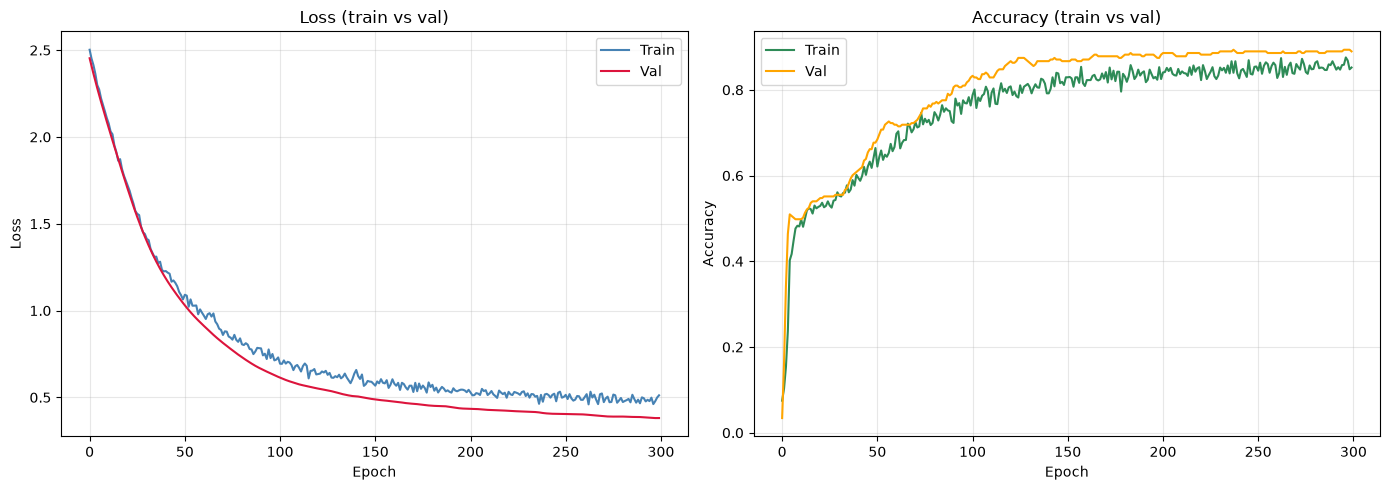

In [15]:
# --- Définir in_channels et out_channels dynamiquement ---
in_channels  = data.x.shape[1]
out_channels = int(data.y.max().item() + 1)

print(f"in_channels={in_channels} | out_channels={out_channels}")

# --- Instancier ---
model = Model(in_channels=in_channels, hidden_channels=16, out_channels=out_channels)

# --- Entraîner (capturer les 5 retours) ---
model, train_losses, val_losses, train_accs, val_accs = train(data, model, epochs=300)

# --- Évaluer sur le test set (une seule fois, à la fin) ---
pred = test(data, model)

# --- Tracer : loss (train vs val) + accuracy (train vs val) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss : train vs val
axes[0].plot(train_losses, label="Train", color="steelblue")
axes[0].plot(val_losses,   label="Val",   color="crimson")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss (train vs val)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Accuracy : train vs val
axes[1].plot(train_accs, label="Train", color="seagreen")
axes[1].plot(val_accs,   label="Val",   color="orange")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy (train vs val)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()